In [1]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "ludhiana_rainfall_target.csv"
)

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

# Features available from the current day's weather.
# Exclude date, target, and calendar columns for now.
feature_columns = [
    "temperature_mean",
    "temperature_max",
    "temperature_min",
    "humidity_mean",
    "dew_point_mean",
    "apparent_temperature_max",
    "precipitation_sum",
    "rain_sum",
    "pressure_mean",
    "cloud_cover_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_gusts_max",
    "month",
    "day_of_week",
    "day_of_year"
]

target_column = "tomorrow_rainfall_mm"

# Train on the earlier 80%; test on the later 20%.
split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

print("DATA PREPARATION SUCCESSFUL")
print("-" * 40)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training dates:", train_df["date"].min().date(),
      "to", train_df["date"].max().date())
print("Testing dates:", test_df["date"].min().date(),
      "to", test_df["date"].max().date())
print("Number of features:", len(feature_columns))
print("Missing values in training features:", X_train.isna().sum().sum())
print("Missing values in testing features:", X_test.isna().sum().sum())
print("Target:", target_column)

print("\nTest target summary:")
print(y_test.describe())


DATA PREPARATION SUCCESSFUL
----------------------------------------
Training rows: 1168
Testing rows: 292
Training dates: 2022-01-01 to 2025-03-13
Testing dates: 2025-03-14 to 2025-12-30
Number of features: 16
Missing values in training features: 0
Missing values in testing features: 0
Target: tomorrow_rainfall_mm

Test target summary:
count    292.000000
mean       2.633562
std        7.839676
min        0.000000
25%        0.000000
50%        0.000000
75%        0.925000
max       75.600000
Name: tomorrow_rainfall_mm, dtype: float64


In [2]:

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

PROJECT_DIR = Path.cwd().parent
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Train the first Random Forest model
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Predict rainfall for the unseen test period
predictions = model.predict(X_test)

# Rainfall cannot be negative
predictions = np.maximum(predictions, 0)

# Evaluate model performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("RANDOM FOREST — FIRST RESULTS")
print("-" * 40)
print(f"MAE:  {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")
print(f"R²:   {r2:.3f}")

# Save the trained model and its feature names
joblib.dump(
    {
        "model": model,
        "feature_columns": feature_columns,
        "target_column": target_column
    },
    MODEL_DIR / "ludhiana_rainfall_random_forest.joblib"
)

# Save test predictions for later comparison
results = pd.DataFrame({
    "date": test_df["date"].values,
    "actual_rainfall_mm": y_test.values,
    "predicted_rainfall_mm": predictions
})

results.to_csv(
    REPORT_DIR / "random_forest_test_predictions.csv",
    index=False
)

print("\nModel saved to:", MODEL_DIR / "ludhiana_rainfall_random_forest.joblib")
print("Test predictions saved to:", REPORT_DIR / "random_forest_test_predictions.csv")

print("\nFirst 10 predictions:")
display(results.head(10).round(2))


RANDOM FOREST — FIRST RESULTS
----------------------------------------
MAE:  2.750 mm
RMSE: 6.679 mm
R²:   0.272

Model saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\models\ludhiana_rainfall_random_forest.joblib
Test predictions saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\reports\random_forest_test_predictions.csv

First 10 predictions:


C:\Users\balve\AppData\Local\Temp\ipykernel_5848\2461515360.py:74: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(results.head(10).round(2))


,date,actual_rainfall_mm,predicted_rainfall_mm
0,2025-03-14,7.9,1.59
1,2025-03-15,0.1,3.20
2,2025-03-16,0.0,1.74
3,2025-03-17,0.0,0.02
4,2025-03-18,0.2,0.09
5,2025-03-19,0.0,4.35
6,2025-03-20,0.0,0.01
7,2025-03-21,0.0,0.01
8,2025-03-22,0.0,2.44
9,2025-03-23,0.0,0.07


In [3]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline: always predict the average rainfall from training data
baseline_prediction = np.full(len(y_test), y_train.mean())

def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE (mm)": mean_absolute_error(actual, predicted),
        "RMSE (mm)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    }

comparison = pd.DataFrame([
    evaluate_model("Training-mean baseline", y_test, baseline_prediction),
    evaluate_model("Random Forest", y_test, predictions)
])

print("MODEL COMPARISON")
display(comparison.round(3))

# Evaluate separately on rainy test days
rainy_mask = y_test.to_numpy() > 0

print("\nRAINY-DAY PERFORMANCE")
print("Rainy test days:", int(rainy_mask.sum()))

if rainy_mask.sum() > 0:
    actual_rainy = y_test.to_numpy()[rainy_mask]
    predicted_rainy = predictions[rainy_mask]

    print(
        "Rainy-day MAE:",
        round(mean_absolute_error(actual_rainy, predicted_rainy), 3),
        "mm"
    )
    print(
        "Rainy-day RMSE:",
        round(np.sqrt(mean_squared_error(actual_rainy, predicted_rainy)), 3),
        "mm"
    )

# Check how often the model predicts rain
print("\nRAIN DETECTION CHECK")
print("Actual rainy days:", int((y_test > 0).sum()))
print("Predictions above 0.1 mm:", int((predictions > 0.1).sum()))
print("Predictions above 1 mm:", int((predictions >= 1).sum()))


MODEL COMPARISON


,Model,MAE (mm),RMSE (mm),R²
0,Training-mean baseline,3.542,7.860,-0.009
1,Random Forest,2.750,6.679,0.272



RAINY-DAY PERFORMANCE
Rainy test days: 112
Rainy-day MAE: 5.714 mm
Rainy-day RMSE: 10.518 mm

RAIN DETECTION CHECK
Actual rainy days: 112
Predictions above 0.1 mm: 223
Predictions above 1 mm: 152


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
9,cloud_cover_mean,0.1832
7,rain_sum,0.1152
4,dew_point_mean,0.1039
6,precipitation_sum,0.0989
10,wind_speed_mean,0.0950
15,day_of_year,0.0749
8,pressure_mean,0.0498
11,wind_speed_max,0.0483
12,wind_gusts_max,0.0469
3,humidity_mean,0.0432


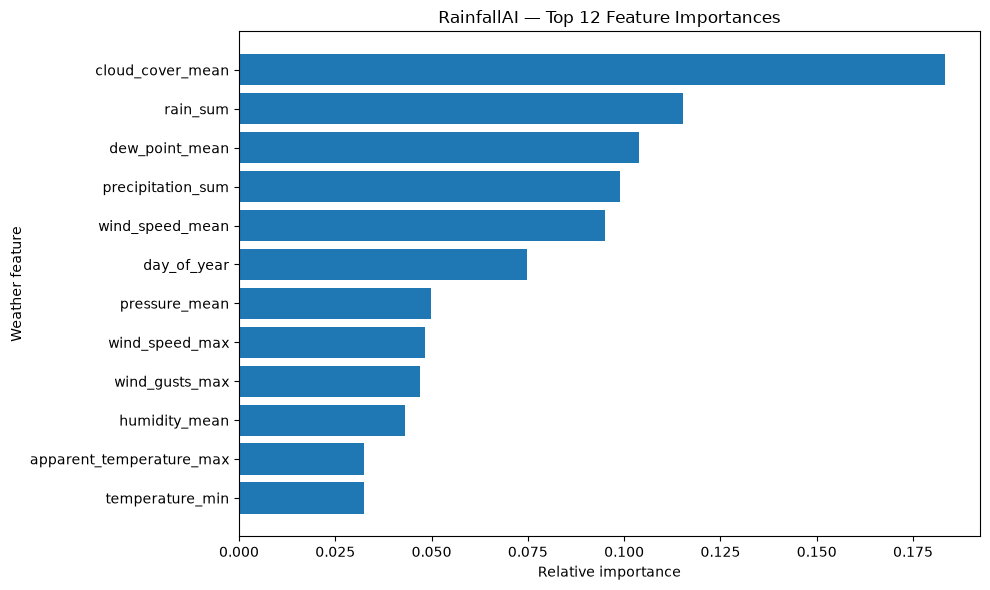

In [4]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from the trained Random Forest
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(importance_df.round(4))

# Visualize the 12 most influential features
top_features = importance_df.head(12).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("RainfallAI — Top 12 Feature Importances")
plt.xlabel("Relative importance")
plt.ylabel("Weather feature")
plt.tight_layout()
plt.show()


In [5]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Load the historical daily forecast data
forecast_path = RAW_DIR / "ludhiana_historical_daily_forecast.csv"
forecast_df = pd.read_csv(forecast_path, parse_dates=["date"])
forecast_df = forecast_df.sort_values("date").reset_index(drop=True)

# Create tomorrow's rainfall target from the following calendar day
forecast_df["tomorrow_rainfall_mm"] = forecast_df["rain_sum"].shift(-1)

# Drop the final date because the next day's target is unavailable
forecast_model_df = forecast_df.dropna(
    subset=["tomorrow_rainfall_mm"]
).copy()

# Save a separate dataset for the new model
output_path = PROCESSED_DIR / "ludhiana_forecast_model_data.csv"
forecast_model_df.to_csv(output_path, index=False)

print("FORECAST MODEL DATA PREPARED")
print("-" * 40)
print("Rows:", len(forecast_model_df))
print("Columns:", len(forecast_model_df.columns))
print("Date range:", forecast_model_df["date"].min().date(),
      "to", forecast_model_df["date"].max().date())
print("Missing values:", forecast_model_df.isna().sum().sum())

print("\nCheck target alignment:")
display(
    forecast_model_df[
        ["date", "rain_sum", "tomorrow_rainfall_mm"]
    ].head(7)
)

print("\nSaved to:", output_path)


FORECAST MODEL DATA PREPARED
----------------------------------------
Rows: 1460
Columns: 10
Date range: 2022-01-01 to 2025-12-30
Missing values: 0

Check target alignment:


,date,rain_sum,tomorrow_rainfall_mm
0,2022-01-01,0.0,0.0
1,2022-01-02,0.0,0.0
2,2022-01-03,0.0,1.0
3,2022-01-04,1.0,24.3
4,2022-01-05,24.3,3.9
5,2022-01-06,3.9,8.2
6,2022-01-07,8.2,59.6



Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_forecast_model_data.csv


In [6]:

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

data_path = PROCESSED_DIR / "ludhiana_forecast_model_data.csv"
df_forecast = pd.read_csv(data_path, parse_dates=["date"])
df_forecast = df_forecast.sort_values("date").reset_index(drop=True)

# Exclude rainfall totals from the current day to avoid a shortcut.
feature_columns_forecast = [
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "dew_point_2m_mean",
    "cloud_cover_mean",
    "wind_speed_10m_max"
]

target_column_forecast = "tomorrow_rainfall_mm"

split_index = int(len(df_forecast) * 0.80)
train_forecast = df_forecast.iloc[:split_index].copy()
test_forecast = df_forecast.iloc[split_index:].copy()

X_train_forecast = train_forecast[feature_columns_forecast]
y_train_forecast = train_forecast[target_column_forecast]
X_test_forecast = test_forecast[feature_columns_forecast]
y_test_forecast = test_forecast[target_column_forecast]

model_forecast = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model_forecast.fit(X_train_forecast, y_train_forecast)
pred_forecast = np.maximum(model_forecast.predict(X_test_forecast), 0)

mae = mean_absolute_error(y_test_forecast, pred_forecast)
rmse = np.sqrt(mean_squared_error(y_test_forecast, pred_forecast))
r2 = r2_score(y_test_forecast, pred_forecast)

print("FORECAST-FEATURE MODEL RESULTS")
print("-" * 40)
print("Training rows:", len(X_train_forecast))
print("Testing rows:", len(X_test_forecast))
print("Testing dates:", test_forecast["date"].min().date(),
      "to", test_forecast["date"].max().date())
print("Features:", feature_columns_forecast)
print(f"MAE:  {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")
print(f"R²:   {r2:.3f}")

joblib.dump(
    {
        "model": model_forecast,
        "feature_columns": feature_columns_forecast,
        "target_column": target_column_forecast
    },
    MODEL_DIR / "ludhiana_forecast_feature_model.joblib"
)

results_forecast = pd.DataFrame({
    "date": test_forecast["date"].values,
    "actual_rainfall_mm": y_test_forecast.values,
    "predicted_rainfall_mm": pred_forecast
})

results_forecast.to_csv(
    REPORT_DIR / "forecast_feature_test_predictions.csv",
    index=False
)

print("\nFirst 10 test predictions:")
display(results_forecast.head(10).round(2))
print("\nModel and predictions saved successfully.")


FORECAST-FEATURE MODEL RESULTS
----------------------------------------
Training rows: 1168
Testing rows: 292
Testing dates: 2025-03-14 to 2025-12-30
Features: ['temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'dew_point_2m_mean', 'cloud_cover_mean', 'wind_speed_10m_max']
MAE:  2.868 mm
RMSE: 6.586 mm
R²:   0.292

First 10 test predictions:


C:\Users\balve\AppData\Local\Temp\ipykernel_5848\1708730464.py:89: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(results_forecast.head(10).round(2))


,date,actual_rainfall_mm,predicted_rainfall_mm
0,2025-03-14,7.9,0.36
1,2025-03-15,0.1,4.22
2,2025-03-16,0.0,0.12
3,2025-03-17,0.0,0.03
4,2025-03-18,0.2,0.06
5,2025-03-19,0.0,0.95
6,2025-03-20,0.0,0.00
7,2025-03-21,0.0,0.00
8,2025-03-22,0.0,0.01
9,2025-03-23,0.0,0.02



Model and predictions saved successfully.


In [7]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_DIR = Path.cwd().parent
REPORT_DIR = PROJECT_DIR / "reports"

model1_path = REPORT_DIR / "random_forest_test_predictions.csv"
model2_path = REPORT_DIR / "forecast_feature_test_predictions.csv"

model1 = pd.read_csv(model1_path, parse_dates=["date"])
model2 = pd.read_csv(model2_path, parse_dates=["date"])

# Rename prediction columns to identify each model
model1 = model1.rename(
    columns={"predicted_rainfall_mm": "model1_prediction_mm"}
)
model2 = model2.rename(
    columns={
        "actual_rainfall_mm": "actual_model2_mm",
        "predicted_rainfall_mm": "model2_prediction_mm"
    }
)

# Align both models by date
comparison_df = model1.merge(model2, on="date", how="inner")

# Verify actual targets match
assert np.allclose(
    comparison_df["actual_rainfall_mm"],
    comparison_df["actual_model2_mm"]
), "The actual target values do not match!"

actual = comparison_df["actual_rainfall_mm"]

def metrics(name, predicted):
    return {
        "Model": name,
        "MAE (mm)": mean_absolute_error(actual, predicted),
        "RMSE (mm)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    }

comparison_results = pd.DataFrame([
    metrics("Model 1 — All features", comparison_df["model1_prediction_mm"]),
    metrics("Model 2 — Forecast features", comparison_df["model2_prediction_mm"])
])

print("COMMON TEST PERIOD")
print("Rows:", len(comparison_df))
print("Dates:", comparison_df["date"].min().date(), "to",
      comparison_df["date"].max().date())

print("\nMODEL COMPARISON")
display(comparison_results.round(3))

print("\nALIGNED PREDICTIONS — FIRST 10 DAYS")
display(
    comparison_df[
        [
            "date",
            "actual_rainfall_mm",
            "model1_prediction_mm",
            "model2_prediction_mm"
        ]
    ].head(10).round(2)
)


COMMON TEST PERIOD
Rows: 292
Dates: 2025-03-14 to 2025-12-30

MODEL COMPARISON


,Model,MAE (mm),RMSE (mm),R²
0,Model 1 — All features,2.750,6.679,0.272
1,Model 2 — Forecast features,2.868,6.586,0.292



ALIGNED PREDICTIONS — FIRST 10 DAYS


C:\Users\balve\AppData\Local\Temp\ipykernel_5848\2019537258.py:67: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,date,actual_rainfall_mm,model1_prediction_mm,model2_prediction_mm
0,2025-03-14,7.9,1.59,0.36
1,2025-03-15,0.1,3.20,4.22
2,2025-03-16,0.0,1.74,0.12
3,2025-03-17,0.0,0.02,0.03
4,2025-03-18,0.2,0.09,0.06
5,2025-03-19,0.0,4.35,0.95
6,2025-03-20,0.0,0.01,0.00
7,2025-03-21,0.0,0.01,0.00
8,2025-03-22,0.0,2.44,0.01
9,2025-03-23,0.0,0.07,0.02


In [8]:

print("Comparison rows:", len(comparison_df))

print("\nMissing values:")
display(comparison_df.isna().sum())

print("\nLast 10 aligned rows:")
display(
    comparison_df[
        [
            "date",
            "actual_rainfall_mm",
            "model1_prediction_mm",
            "model2_prediction_mm"
        ]
    ].tail(10)
)

print("\nPrediction ranges:")
print(
    comparison_df[
        ["model1_prediction_mm", "model2_prediction_mm"]
    ].describe().round(2)
)


Comparison rows: 292

Missing values:


date                    0
actual_rainfall_mm      0
model1_prediction_mm    0
actual_model2_mm        0
model2_prediction_mm    0
dtype: int64


Last 10 aligned rows:


,date,actual_rainfall_mm,model1_prediction_mm,model2_prediction_mm
282,2025-12-21,0.0,1.707629,6.991160
283,2025-12-22,0.0,0.694177,0.797368
284,2025-12-23,0.0,0.396478,0.401870
285,2025-12-24,0.0,0.005930,0.015287
286,2025-12-25,0.0,0.613839,0.539500
287,2025-12-26,0.0,0.357065,0.527958
288,2025-12-27,0.0,1.480248,0.869358
289,2025-12-28,0.0,2.853814,0.402201
290,2025-12-29,0.0,1.036713,1.156022
291,2025-12-30,0.0,1.157935,0.634467



Prediction ranges:
       model1_prediction_mm  model2_prediction_mm
count                292.00                292.00
mean                   2.73                  2.86
std                    3.50                  4.01
min                    0.00                  0.00
25%                    0.12                  0.08
50%                    1.06                  0.63
75%                    4.56                  5.31
max                   17.32                 25.51


In [9]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

data_path = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "ludhiana_forecast_model_data.csv"
)

forecast_data = pd.read_csv(data_path, parse_dates=["date"])

print("Dataset shape:", forecast_data.shape)
print("\nDate range:")
print(forecast_data["date"].min(), "to", forecast_data["date"].max())

print("\nColumns:")
print(forecast_data.columns.tolist())

print("\nFirst 5 records:")
display(forecast_data.head())

print("\nLast 5 records:")
display(forecast_data.tail())

print("\nMissing values:")
display(forecast_data.isna().sum())


Dataset shape: (1460, 10)

Date range:
2022-01-01 00:00:00 to 2025-12-30 00:00:00

Columns:
['date', 'precipitation_sum', 'rain_sum', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'dew_point_2m_mean', 'cloud_cover_mean', 'wind_speed_10m_max', 'tomorrow_rainfall_mm']

First 5 records:


,date,precipitation_sum,rain_sum,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,wind_speed_10m_max,tomorrow_rainfall_mm
0,2022-01-01,0.0,0.0,17.7,5.3,84,7.2,59,9.9,0.0
1,2022-01-02,0.0,0.0,18.0,5.3,82,7.4,90,10.2,0.0
2,2022-01-03,0.0,0.0,19.6,6.4,77,7.6,96,10.6,1.0
3,2022-01-04,1.0,1.0,14.7,9.9,85,10.0,99,8.3,24.3
4,2022-01-05,24.3,24.3,13.9,10.4,94,11.4,100,10.4,3.9



Last 5 records:


,date,precipitation_sum,rain_sum,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,wind_speed_10m_max,tomorrow_rainfall_mm
1455,2025-12-26,0.0,0.0,19.6,8.7,82,9.7,60,6.8,0.0
1456,2025-12-27,0.0,0.0,18.6,8.4,86,10.4,72,8.4,0.0
1457,2025-12-28,0.0,0.0,18.6,8.0,86,9.9,86,8.4,0.0
1458,2025-12-29,0.0,0.0,17.5,8.9,86,9.4,83,7.9,0.0
1459,2025-12-30,0.0,0.0,18.5,9.7,86,10.1,53,10.9,0.0



Missing values:


date                         0
precipitation_sum            0
rain_sum                     0
temperature_2m_max           0
temperature_2m_min           0
relative_humidity_2m_mean    0
dew_point_2m_mean            0
cloud_cover_mean             0
wind_speed_10m_max           0
tomorrow_rainfall_mm         0
dtype: int64

In [10]:

import pandas as pd
import numpy as np
import joblib

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_DIR = Path.cwd().parent
DATA_PATH = PROJECT_DIR / "data" / "processed" / "ludhiana_2025_ml_training_data.csv"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

features = [
    "temperature_mean_c",
    "humidity_mean_pct",
    "dew_point_mean_c",
    "cloud_cover_mean_pct",
    "wind_speed_mean_kmh"
]
target = "observed_rainfall_mm"

split_index = int(len(df) * 0.8)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
predictions = np.maximum(model.predict(X_test), 0)

# Baseline: predict the average rainfall from the training period.
baseline_predictions = np.full(len(y_test), y_train.mean())

def calculate_metrics(name, actual, predicted):
    return {
        "Model": name,
        "MAE (mm)": mean_absolute_error(actual, predicted),
        "RMSE (mm)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    }

results = pd.DataFrame([
    calculate_metrics("Random Forest", y_test, predictions),
    calculate_metrics("Training-mean baseline", y_test, baseline_predictions)
])

print("TRAINING PERIOD:")
print(train_df["date"].min().date(), "to", train_df["date"].max().date())

print("\nTEST PERIOD:")
print(test_df["date"].min().date(), "to", test_df["date"].max().date())

print("\nMODEL EVALUATION:")
display(results.round(3))

test_results = pd.DataFrame({
    "date": test_df["date"],
    "actual_rainfall_mm": y_test.to_numpy(),
    "predicted_rainfall_mm": predictions
})

test_results.to_csv(REPORT_DIR / "ludhiana_2025_test_predictions.csv", index=False)
joblib.dump(model, MODEL_DIR / "ludhiana_2025_rainfall_model.joblib")

print("\nSaved model:", MODEL_DIR / "ludhiana_2025_rainfall_model.joblib")
print("Saved predictions:", REPORT_DIR / "ludhiana_2025_test_predictions.csv")


TRAINING PERIOD:
2025-01-01 to 2025-10-19

TEST PERIOD:
2025-10-20 to 2025-12-31

MODEL EVALUATION:


,Model,MAE (mm),RMSE (mm),R²
0,Random Forest,2.731,6.606,-35885.204
1,Training-mean baseline,3.092,3.093,-7864.670



Saved model: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\models\ludhiana_2025_rainfall_model.joblib
Saved predictions: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\reports\ludhiana_2025_test_predictions.csv


In [11]:

# STEP 61 — Load data for model training

from pathlib import Path
import pandas as pd
import numpy as np

data_path = Path("../data/raw/ludhiana_rainfall_reference_2022_2025.csv")

if not data_path.exists():
    data_path = Path("data/raw/ludhiana_rainfall_reference_2022_2025.csv")

training_df = pd.read_csv(data_path)
training_df["date"] = pd.to_datetime(training_df["date"])
training_df = training_df.sort_values("date").reset_index(drop=True)

print("TRAINING DATA LOADED")
print("-" * 35)
print("Dataset shape:", training_df.shape)
print("First date:", training_df["date"].min().date())
print("Last date:", training_df["date"].max().date())
print("Missing values:", training_df.isna().sum().sum())
print("\nFirst 5 rows:")
print(training_df.head().to_string(index=False))


TRAINING DATA LOADED
-----------------------------------
Dataset shape: (1461, 3)
First date: 2022-01-01
Last date: 2025-12-31
Missing values: 0

First 5 rows:
      date  observed_precipitation_mm  observed_rainfall_mm
2022-01-01                        0.0                   0.0
2022-01-02                        0.0                   0.0
2022-01-03                        0.0                   0.0
2022-01-04                        1.0                   1.0
2022-01-05                       24.3                  24.3


In [12]:

# STEP 62 — Create prediction target

training_df["tomorrow_rainfall_mm"] = (
    training_df["observed_rainfall_mm"].shift(-1)
)

training_df["month"] = training_df["date"].dt.month
training_df["day_of_year"] = training_df["date"].dt.dayofyear
training_df["day_of_week"] = training_df["date"].dt.dayofweek

training_df["season"] = training_df["month"].apply(
    lambda m: (
        "Winter" if m in [12, 1, 2] else
        "Summer" if m in [3, 4, 5] else
        "Monsoon" if m in [6, 7, 8, 9] else
        "Post-Monsoon"
    )
)

training_df = training_df.dropna(
    subset=["tomorrow_rainfall_mm"]
).reset_index(drop=True)

print("Rows for training:", len(training_df))
print(training_df[[
    "date", "observed_rainfall_mm", "tomorrow_rainfall_mm",
    "month", "season"
]].head())


Rows for training: 1460
        date  observed_rainfall_mm  tomorrow_rainfall_mm  month  season
0 2022-01-01                   0.0                   0.0      1  Winter
1 2022-01-02                   0.0                   0.0      1  Winter
2 2022-01-03                   0.0                   1.0      1  Winter
3 2022-01-04                   1.0                  24.3      1  Winter
4 2022-01-05                  24.3                   3.9      1  Winter


In [14]:

# STEP 63 — Select features and target

feature_columns = [
    "observed_rainfall_mm",
    "month",
    "day_of_year",
    "day_of_week",
    "season"
]

X = training_df[feature_columns].copy()
y = training_df["tomorrow_rainfall_mm"].copy()

print("Feature columns:", feature_columns)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget summary:")
print(y.describe())


Feature columns: ['observed_rainfall_mm', 'month', 'day_of_year', 'day_of_week', 'season']
X shape: (1460, 5)
y shape: (1460,)

Target summary:
count    1460.000000
mean        2.074247
std         6.432952
min         0.000000
25%         0.000000
50%         0.000000
75%         0.700000
max        75.600000
Name: tomorrow_rainfall_mm, dtype: float64


In [15]:

# STEP 64 — Encode categorical features

X_encoded = pd.get_dummies(
    X,
    columns=["season"],
    dtype=int
)

print("Encoded feature columns:")
print(X_encoded.columns.tolist())
print("\nEncoded shape:", X_encoded.shape)
print(X_encoded.head())


Encoded feature columns:
['observed_rainfall_mm', 'month', 'day_of_year', 'day_of_week', 'season_Monsoon', 'season_Post-Monsoon', 'season_Summer', 'season_Winter']

Encoded shape: (1460, 8)
   observed_rainfall_mm  month  day_of_year  day_of_week  season_Monsoon  \
0                   0.0      1            1            5               0   
1                   0.0      1            2            6               0   
2                   0.0      1            3            0               0   
3                   1.0      1            4            1               0   
4                  24.3      1            5            2               0   

   season_Post-Monsoon  season_Summer  season_Winter  
0                    0              0              1  
1                    0              0              1  
2                    0              0              1  
3                    0              0              1  
4                    0              0              1  


In [16]:

# STEP 65 — Chronological train/test split

split_index = int(len(training_df) * 0.80)

X_train = X_encoded.iloc[:split_index].copy()
X_test = X_encoded.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training dates:",
      training_df["date"].iloc[0].date(), "to",
      training_df["date"].iloc[split_index - 1].date())
print("Testing dates:",
      training_df["date"].iloc[split_index].date(), "to",
      training_df["date"].iloc[-1].date())


Training rows: 1168
Testing rows: 292
Training dates: 2022-01-01 to 2025-03-13
Testing dates: 2025-03-14 to 2025-12-30


In [17]:

# STEP 66 — Baseline persistence prediction

baseline_predictions = X_test["observed_rainfall_mm"].to_numpy()
baseline_mae = np.mean(np.abs(y_test.to_numpy() - baseline_predictions))
baseline_rmse = np.sqrt(
    np.mean((y_test.to_numpy() - baseline_predictions) ** 2)
)

print("BASELINE RESULTS")
print("MAE:", round(baseline_mae, 3), "mm")
print("RMSE:", round(baseline_rmse, 3), "mm")


BASELINE RESULTS
MAE: 3.224 mm
RMSE: 9.164 mm


In [18]:

# STEP 67 — Train Random Forest model

from sklearn.ensemble import RandomForestRegressor

random_forest = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

rf_predictions = random_forest.predict(X_test)

print("Random Forest training completed.")
print("Sample predictions:", np.round(rf_predictions[:10], 2))


Random Forest training completed.
Sample predictions: [6.46 7.   1.17 0.08 0.13 1.76 0.11 0.09 0.12 0.2 ]


In [19]:

# STEP 68 — Train Extra Trees model

from sklearn.ensemble import ExtraTreesRegressor

extra_trees = ExtraTreesRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

extra_trees.fit(X_train, y_train)

et_predictions = extra_trees.predict(X_test)

print("Extra Trees training completed.")
print("Sample predictions:", np.round(et_predictions[:10], 2))


Extra Trees training completed.
Sample predictions: [5.29 4.71 0.7  0.08 0.18 1.21 0.62 1.4  0.3  0.55]


In [20]:

# STEP 69 — Train Gradient Boosting model

from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    loss="huber",
    random_state=42
)

gradient_boosting.fit(X_train, y_train)

gb_predictions = gradient_boosting.predict(X_test)

print("Gradient Boosting training completed.")
print("Sample predictions:", np.round(gb_predictions[:10], 2))


Gradient Boosting training completed.
Sample predictions: [1.55 2.22 0.53 0.19 0.23 0.7  0.23 0.23 0.23 0.23]


In [21]:

# STEP 70 — Compare model performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

predictions_by_model = {
    "Persistence Baseline": baseline_predictions,
    "Random Forest": rf_predictions,
    "Extra Trees": et_predictions,
    "Gradient Boosting": gb_predictions
}

results = []

for model_name, predictions in predictions_by_model.items():
    results.append({
        "Model": model_name,
        "MAE_mm": mean_absolute_error(y_test, predictions),
        "RMSE_mm": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("MAE_mm")

print(results_df.round(3).to_string(index=False))


               Model  MAE_mm  RMSE_mm     R2
   Gradient Boosting   2.760    7.851  0.005
         Extra Trees   2.943    7.331  0.133
       Random Forest   3.035    7.349  0.129
Persistence Baseline   3.224    9.164 -0.355


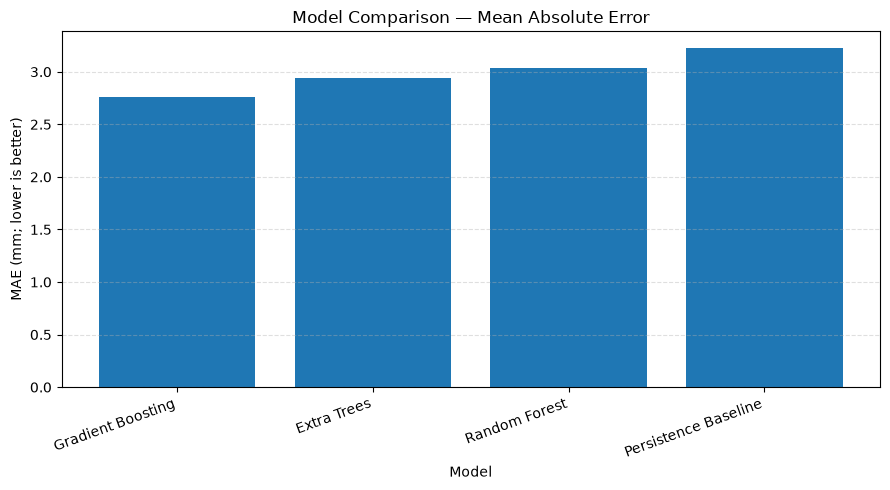

In [22]:

# STEP 71 — Compare MAE visually

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["MAE_mm"])

plt.title("Model Comparison — Mean Absolute Error")
plt.xlabel("Model")
plt.ylabel("MAE (mm; lower is better)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [23]:

# STEP 72 — Select the best model

best_model_name = results_df.iloc[0]["Model"]

model_objects = {
    "Random Forest": random_forest,
    "Extra Trees": extra_trees,
    "Gradient Boosting": gradient_boosting
}

if best_model_name == "Persistence Baseline":
    best_model = None
    print("The baseline performed best. Do not deploy a weaker ML model.")
else:
    best_model = model_objects[best_model_name]
    print("Best model by test MAE:", best_model_name)

print("Best measured MAE:",
      round(results_df.iloc[0]["MAE_mm"], 3), "mm")


Best model by test MAE: Gradient Boosting
Best measured MAE: 2.76 mm


             Feature  Importance
observed_rainfall_mm      0.7998
         day_of_year      0.1387
      season_Monsoon      0.0601
         day_of_week      0.0013
               month      0.0000
 season_Post-Monsoon      0.0000
       season_Summer      0.0000
       season_Winter      0.0000


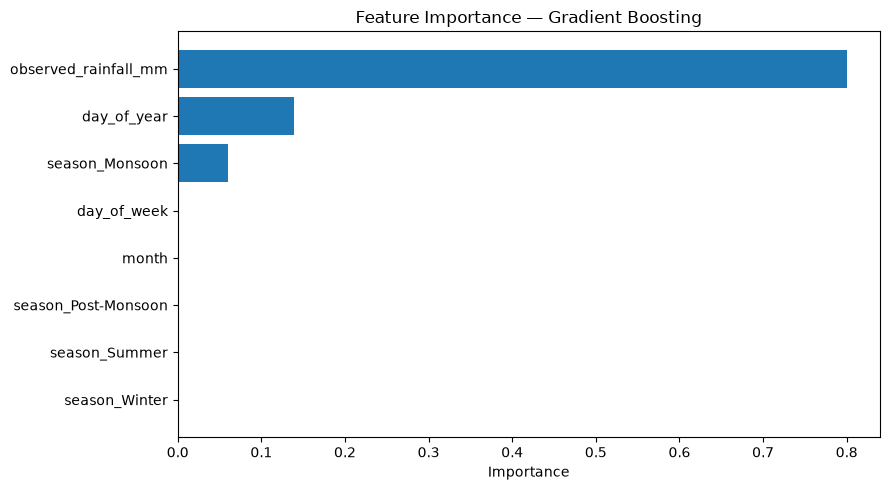

In [24]:

# STEP 73 — Feature importance

if best_model is not None and hasattr(best_model, "feature_importances_"):
    importance_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": best_model.feature_importances_
    }).sort_values("Importance", ascending=False)

    print(importance_df.round(4).to_string(index=False))

    plt.figure(figsize=(9, 5))
    plt.barh(
        importance_df["Feature"][::-1],
        importance_df["Importance"][::-1]
    )
    plt.title(f"Feature Importance — {best_model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance unavailable for the selected model.")


In [25]:

# STEP 74 — Save model artifacts

import joblib

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

model_dir = project_root / "model"
model_dir.mkdir(parents=True, exist_ok=True)

if best_model is not None:
    joblib.dump(best_model, model_dir / "rainfall_model.joblib")

joblib.dump(
    {
        "feature_columns": feature_columns,
        "encoded_feature_columns": X_encoded.columns.tolist(),
        "target_column": "tomorrow_rainfall_mm",
        "rain_threshold_mm": 0.1,
        "best_model_name": best_model_name
    },
    model_dir / "feature_config.joblib"
)

print("Model folder:", model_dir.resolve())
print("Selected model:", best_model_name)
print("Configuration saved.")


Model folder: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\model
Selected model: Gradient Boosting
Configuration saved.


In [26]:

# STEP 75 — Save training results

processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    processed_dir / "model_training_comparison.csv",
    index=False
)

print("Training phase completed.")
print("Results saved to:",
      (processed_dir / "model_training_comparison.csv").resolve())
print("\nFinal comparison:")
print(results_df.round(3).to_string(index=False))


Training phase completed.
Results saved to: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\model_training_comparison.csv

Final comparison:
               Model  MAE_mm  RMSE_mm     R2
   Gradient Boosting   2.760    7.851  0.005
         Extra Trees   2.943    7.331  0.133
       Random Forest   3.035    7.349  0.129
Persistence Baseline   3.224    9.164 -0.355


In [27]:

# STEP 13 — Inspect rainfall distribution

print("TRAINING DATA")
print("-" * 40)
print("Training rows:", len(train_df))
print("Training dates:", train_df["date"].min(), "to", train_df["date"].max())
print("Rainfall total:", round(y_train.sum(), 2), "mm")
print("Average rainfall:", round(y_train.mean(), 3), "mm")
print("Maximum rainfall:", round(y_train.max(), 2), "mm")
print("Days with rainfall >= 1 mm:", int((y_train >= 1).sum()))
print("Days with zero rainfall:", int((y_train == 0).sum()))

print("\nTESTING DATA")
print("-" * 40)
print("Testing rows:", len(test_df))
print("Testing dates:", test_df["date"].min(), "to", test_df["date"].max())
print("Rainfall total:", round(y_test.sum(), 2), "mm")
print("Average rainfall:", round(y_test.mean(), 3), "mm")
print("Maximum rainfall:", round(y_test.max(), 2), "mm")
print("Days with rainfall >= 1 mm:", int((y_test >= 1).sum()))
print("Days with zero rainfall:", int((y_test == 0).sum()))


TRAINING DATA
----------------------------------------
Training rows: 292
Training dates: 2025-01-01 00:00:00 to 2025-10-19 00:00:00
Rainfall total: 2229.6 mm
Average rainfall: 1.909 mm
Maximum rainfall: 71.8 mm
Days with rainfall >= 1 mm: 247
Days with zero rainfall: 765

TESTING DATA
----------------------------------------
Testing rows: 73
Testing dates: 2025-10-20 00:00:00 to 2025-12-31 00:00:00
Rainfall total: 798.8 mm
Average rainfall: 2.736 mm
Maximum rainfall: 75.6 mm
Days with rainfall >= 1 mm: 75
Days with zero rainfall: 174


In [28]:

print("Data consistency check")
print("-" * 40)

print("df shape:", df.shape)
print("train_df shape:", train_df.shape)
print("test_df shape:", test_df.shape)

print("\nTarget lengths:")
print("y_train:", len(y_train))
print("y_test:", len(y_test))

print("\nTarget counts:")
print("Training target values:")
print(y_train.value_counts().head(10))

print("\nTesting target values:")
print(y_test.value_counts().head(10))

print("\nTarget summary:")
print("Training:", y_train.describe())
print("\nTesting:", y_test.describe())


Data consistency check
----------------------------------------
df shape: (365, 7)
train_df shape: (292, 7)
test_df shape: (73, 7)

Target lengths:
y_train: 1168
y_test: 292

Target counts:
Training target values:
tomorrow_rainfall_mm
0.0    765
0.1     33
0.3     22
0.2     21
0.4     16
0.7     15
0.9     14
0.5     13
1.2     12
0.6     11
Name: count, dtype: int64

Testing target values:
tomorrow_rainfall_mm
0.0    174
0.1     16
0.7      6
0.3      5
0.2      4
0.5      4
2.3      3
0.8      3
1.9      3
1.5      3
Name: count, dtype: int64

Target summary:
Training: count    1168.000000
mean        1.908904
std         6.007979
min         0.000000
25%         0.000000
50%         0.000000
75%         0.600000
max        71.800000
Name: tomorrow_rainfall_mm, dtype: float64

Testing: count    292.000000
mean       2.735616
std        7.885379
min        0.000000
25%        0.000000
50%        0.000000
75%        1.025000
max       75.600000
Name: tomorrow_rainfall_mm, dtype: float

In [29]:

# STEP 15 — Rebuild the train/test variables consistently

df = df.sort_values("date").reset_index(drop=True)

feature_columns = [
    "temperature_mean",
    "temperature_max",
    "temperature_min",
    "humidity_mean",
    "dew_point_mean",
    "apparent_temperature_max",
    "precipitation_sum",
    "rain_sum",
    "pressure_mean",
    "cloud_cover_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_gusts_max",
    "month",
    "day_of_week",
    "day_of_year"
]

target_column = "tomorrow_rainfall_mm"

# Confirm every required column exists
required_columns = feature_columns + [target_column]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns in df: {missing_columns}")

# Use only the dataset currently loaded in df
split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

print("Training rows:", len(X_train))
print("Training target values:", len(y_train))
print("Testing rows:", len(X_test))
print("Testing target values:", len(y_test))

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

print("\nVariables rebuilt successfully!")


ValueError: Missing columns in df: ['temperature_mean', 'temperature_max', 'temperature_min', 'humidity_mean', 'dew_point_mean', 'apparent_temperature_max', 'precipitation_sum', 'rain_sum', 'pressure_mean', 'cloud_cover_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_gusts_max', 'month', 'day_of_week', 'day_of_year', 'tomorrow_rainfall_mm']

In [30]:

# STEP 16 — Identify and load the correct training dataset

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent

data_path = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "ludhiana_rainfall_target.csv"
)

df_model = pd.read_csv(data_path, parse_dates=["date"])
df_model = df_model.sort_values("date").reset_index(drop=True)

print("Dataset loaded:", data_path.name)
print("Shape:", df_model.shape)
print("\nAvailable columns:")
print(df_model.columns.tolist())

print("\nDate range:")
print(df_model["date"].min(), "to", df_model["date"].max())

print("\nFirst five rows:")
display(df_model.head())


Dataset loaded: ludhiana_rainfall_target.csv
Shape: (1460, 18)

Available columns:
['date', 'temperature_mean', 'temperature_max', 'temperature_min', 'humidity_mean', 'dew_point_mean', 'apparent_temperature_max', 'precipitation_sum', 'rain_sum', 'pressure_mean', 'cloud_cover_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_gusts_max', 'month', 'day_of_week', 'day_of_year', 'tomorrow_rainfall_mm']

Date range:
2022-01-01 00:00:00 to 2025-12-30 00:00:00

First five rows:


,date,temperature_mean,temperature_max,temperature_min,humidity_mean,dew_point_mean,apparent_temperature_max,precipitation_sum,rain_sum,pressure_mean,cloud_cover_mean,wind_speed_mean,wind_speed_max,wind_gusts_max,month,day_of_week,day_of_year,tomorrow_rainfall_mm
0,2022-01-01,10.125000,17.7,5.3,84.041667,7.175000,15.6,0.0,0.0,1022.170833,59.208333,6.791667,9.9,20.9,1,5,1,0.0
1,2022-01-02,10.758333,18.0,5.3,81.833333,7.391667,16.3,0.0,0.0,1020.812500,90.250000,7.391667,10.2,19.4,1,6,2,0.0
2,2022-01-03,12.045833,19.6,6.4,76.916667,7.654167,17.3,0.0,0.0,1018.716667,96.333333,7.054167,10.6,22.0,1,0,3,1.0
3,2022-01-04,12.558333,14.7,9.9,84.791667,10.020833,14.6,1.0,1.0,1018.150000,98.750000,5.808333,8.3,14.8,1,1,4,24.3
4,2022-01-05,12.391667,13.9,10.4,93.625000,11.400000,13.4,24.3,24.3,1016.308333,100.000000,6.008333,10.4,20.5,1,2,5,3.9
